# Rajuk Image-Level Classifier — CUDA Bagged SVM

This version replaces the high-variance single SVM with a validation-selected **CUDA bagging ensemble**. Each bootstrap member is a multiclass SVM trained with squared hinge loss on the NVIDIA GPU; RBF candidates use GPU random Fourier features. It uses robust HOG, colour, and spatial features, aggregates augmented copies by original image ID, and keeps the test set untouched until the final evaluation.

The previous notebook reported **0.2917 validation accuracy** and **0.5417 test accuracy**. This notebook will not save a replacement model unless both scores are beaten. It also exports the test-set misclassified image names to CSV and plots an empirical bias–variance decomposition.

## 1. Local Setup (no Google Drive needed)

Images and labels are read directly from the local Final Project folders, using the same input setup as `rajuk_cnn_improved_trained.ipynb`.

In [14]:
# Running locally — no Google Drive mount is required.
# A CUDA-enabled PyTorch installation is required.
print('Running locally — reading images directly from the project folders.')

Running locally — reading images directly from the project folders.


In [15]:
import os
import re
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F

from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, log_loss,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError(
        'CUDA is required for this notebook, but PyTorch cannot see an NVIDIA GPU. '
        'Install a CUDA-enabled PyTorch build and the current NVIDIA driver.'
    )
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda')
torch.backends.cudnn.benchmark = True
print(f'CUDA device: {torch.cuda.get_device_name(0)}')
print(f'PyTorch CUDA build: {torch.version.cuda}')

CUDA device: NVIDIA GeForce GTX 1650
PyTorch CUDA build: 12.4


## 2. Configuration

In [16]:
# Same local input root used by rajuk_cnn_improved_trained.ipynb.
DRIVE_BASE    = Path(r'D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files')
AUGMENTED_DIR = DRIVE_BASE / 'Augmented_raw_data'
REAL_DIR      = DRIVE_BASE / 'raw_data' / 'final train image'
XLSX_PATH     = DRIVE_BASE / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = DRIVE_BASE / 'Real ML_DataSet.csv'

# Save generated artifacts beside the notebook/current working directory.
OUTPUT_DIR = Path.cwd()

# Same path checks used by the CNN notebook.
for label, path in [('Augmented dir', AUGMENTED_DIR), ('Real images dir', REAL_DIR)]:
    print(f'  {label:16s}: {path}  ->  {"OK" if path.exists() else "MISSING!"}')
if not (XLSX_PATH.exists() or CSV_PATH.exists()):
    print('  WARNING: neither the .xlsx nor the .csv label file was found!')

CLASS_NAMES  = ['negative', 'moderate', 'positive']
ALLOWED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
IMAGE_SIZE   = (64, 64)

# Same subject split as the CNN notebook: 70% train, 10% validation, 20% test.
# Every augmented copy follows its original image ID into the same split.
TEST_FRACTION = 0.20
VAL_FRACTION  = 0.10

# The old notebook's saved results. These are strict acceptance thresholds.
REFERENCE_VAL_ACCURACY  = 0.2917
REFERENCE_TEST_ACCURACY = 0.5417

# PCA is fitted on one robust prototype per original image ID, not on every
# augmented copy. This prevents heavily augmented subjects dominating the fit.
PCA_COMPONENTS = 64

# CUDA SVM settings. RBF candidates use random Fourier features followed by a
# multiclass linear SVM optimized with squared hinge loss entirely on the GPU.
CUDA_SVM_EPOCHS   = 300
CUDA_SVM_LR       = 0.02
RFF_COMPONENTS    = 256
CUDA_LOG_INTERVAL = 100
CUDA_FEATURE_BATCH_SIZE = 64
IMAGE_IO_WORKERS = min(8, os.cpu_count() or 1)

# All candidates are bagging models. Selection uses validation accuracy first,
# macro-F1 second, and log-loss only as a final tie-breaker.
BAGGING_CANDIDATES = [
    dict(kernel='rbf',    C=0.5, gamma='scale', n_estimators=31, max_samples=0.75, max_features=0.75),
    dict(kernel='rbf',    C=1.0, gamma='scale', n_estimators=31, max_samples=0.80, max_features=0.85),
    dict(kernel='rbf',    C=2.0, gamma='scale', n_estimators=41, max_samples=0.85, max_features=0.90),
    dict(kernel='rbf',    C=5.0, gamma='scale', n_estimators=41, max_samples=0.90, max_features=1.00),
    dict(kernel='rbf',   C=10.0, gamma=0.01,    n_estimators=41, max_samples=0.85, max_features=0.90),
    dict(kernel='linear', C=0.01, gamma='scale', n_estimators=31, max_samples=0.75, max_features=0.75),
    dict(kernel='linear', C=0.05, gamma='scale', n_estimators=41, max_samples=0.85, max_features=0.90),
    dict(kernel='linear', C=0.10, gamma='scale', n_estimators=41, max_samples=0.90, max_features=1.00),
]

MISCLASSIFIED_CSV = OUTPUT_DIR / 'misclassified_images_bagged_svm.csv'
BIAS_VARIANCE_PNG = OUTPUT_DIR / 'bias_variance_bagged_svm.png'
MODEL_PATH        = OUTPUT_DIR / 'rajuk_bagged_svm.pkl'

print(f'{len(BAGGING_CANDIDATES)} bagging candidates configured.')
print(f'Validation fraction: {VAL_FRACTION:.0%} | Test fraction: {TEST_FRACTION:.0%}')

  Augmented dir   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Augmented_raw_data  ->  OK
  Real images dir : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\raw_data\final train image  ->  OK
8 bagging candidates configured.
Validation fraction: 10% | Test fraction: 20%


## 3. Load labels and create a leakage-free subject split

In [17]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(frame, target):
    return next((c for c in frame.columns if normalize_header(c) == target), None)

def normalize_level(value):
    if pd.isna(value):
        return None
    mapping = {
        'p': 'positive', 'positive': 'positive',
        'm': 'moderate', 'moderate': 'moderate',
        'n': 'negative', 'negative': 'negative'
    }
    return mapping.get(str(value).strip().lower())

if XLSX_PATH.exists():
    df = pd.read_excel(XLSX_PATH)
    source_path = XLSX_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(f'No label file found under {DRIVE_BASE}.')

level_col = find_column(df, 'levelpositivemoderatenegative') or find_column(df, 'level')
if level_col is None:
    raise ValueError('The positive/moderate/negative level column was not found.')

label_lookup = {name: i for i, name in enumerate(CLASS_NAMES)}
label_map = {
    row_index: label_lookup[level]
    for row_index, value in enumerate(df[level_col].tolist(), start=1)
    if (level := normalize_level(value)) is not None
}
print(f'Loaded {len(label_map):,} valid labels from {source_path.name}.')

Loaded 372 valid labels from Real ML_DataSet.csv.


In [18]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.strip().lower())
    return int(match.group(1)) if match else None

def collect_images(base_dir):
    records = []
    skipped_no_index = 0
    skipped_no_label = 0
    if not base_dir.exists():
        return records, skipped_no_index, skipped_no_label
    for path in base_dir.rglob('*'):
        if not (path.is_file() and path.suffix.lower() in ALLOWED_EXTS):
            continue
        image_id = parse_image_index(path.stem.strip())
        if image_id is None:
            skipped_no_index += 1
            continue
        if image_id not in label_map:
            skipped_no_label += 1
            continue
        records.append((path, label_map[image_id], image_id))
    return records, skipped_no_index, skipped_no_label

aug_records,  skipped_aug_index,  skipped_aug_label  = collect_images(AUGMENTED_DIR)
real_records, skipped_real_index, skipped_real_label = collect_images(REAL_DIR)

unique_ids = np.array(sorted({image_id for _, _, image_id in real_records}))
unique_y   = np.array([label_map[image_id] for image_id in unique_ids])

trainval_ids, test_ids = train_test_split(
    unique_ids, test_size=TEST_FRACTION, random_state=SEED, stratify=unique_y
)
trainval_y = np.array([label_map[image_id] for image_id in trainval_ids])
validation_relative_fraction = VAL_FRACTION / (1.0 - TEST_FRACTION)
train_ids, val_ids = train_test_split(
    trainval_ids,
    test_size=validation_relative_fraction,
    random_state=SEED,
    stratify=trainval_y,
)

train_ids, val_ids, test_ids = set(train_ids), set(val_ids), set(test_ids)

# Match the CNN input pipeline: real and augmented copies follow their original
# image ID into the same train, validation, or test subject split.
all_records = aug_records + real_records
train_records = [record for record in all_records if record[2] in train_ids]
val_records   = [record for record in all_records if record[2] in val_ids]
test_records  = [record for record in all_records if record[2] in test_ids]

assert train_ids.isdisjoint(val_ids | test_ids)
assert val_ids.isdisjoint(test_ids)
assert all(r[2] in train_ids for r in train_records)
assert all(r[2] in val_ids for r in val_records)
assert all(r[2] in test_ids for r in test_records)

print(f'Augmented images found : {len(aug_records):,}')
print(f'Real images found      : {len(real_records):,}')
print(f'Skipped (no index)     : {skipped_aug_index + skipped_real_index:,}')
print(f'Skipped (no label)     : {skipped_aug_label + skipped_real_label:,}')
print(f'Train (real + aug)     : {len(train_records):,} ({len(train_ids)} unique IDs)')
print(f'Validation (real + aug): {len(val_records):,} ({len(val_ids)} unique IDs)')
print(f'Test (real + aug)      : {len(test_records):,} ({len(test_ids)} unique IDs)')
print(f'Total accounted        : {len(train_records) + len(val_records) + len(test_records):,}')

Augmented images found : 5,968
Real images found      : 373
Skipped (no index)     : 0
Skipped (no label)     : 17
Train (real + aug)     : 4,420 (259 unique IDs)
Validation (real + aug): 646 (38 unique IDs)
Test (real + aug)      : 1,275 (75 unique IDs)
Total accounted        : 6,341


## 4. CUDA-batched robust feature extraction

Image files are decoded concurrently on the CPU, then transferred in batches to CUDA. HOG shape/edge features, HSV colour histograms, the 8×8 spatial colour grid, and global colour moments are all computed on the GPU.

In [19]:
def load_rgb_image(image_path):
    """Decode and resize one image on CPU; feature computation happens on CUDA."""
    with Image.open(image_path) as image:
        image = image.convert('RGB').resize(IMAGE_SIZE, Image.BILINEAR)
        return np.asarray(image, dtype=np.float32) / 255.0


def rgb_to_hsv_cuda(rgb):
    """Vectorized RGB-to-HSV conversion for Bx3xHxW CUDA tensors."""
    red, green, blue = rgb[:, 0], rgb[:, 1], rgb[:, 2]
    maximum, max_indices = rgb.max(dim=1)
    minimum = rgb.min(dim=1).values
    delta = maximum - minimum
    safe_delta = delta.clamp_min(1e-8)

    hue_red = torch.remainder((green - blue) / safe_delta, 6.0)
    hue_green = (blue - red) / safe_delta + 2.0
    hue_blue = (red - green) / safe_delta + 4.0
    hue = torch.where(max_indices == 0, hue_red, hue_green)
    hue = torch.where(max_indices == 2, hue_blue, hue)
    hue = torch.where(delta > 1e-8, torch.remainder(hue / 6.0, 1.0), 0.0)
    saturation = torch.where(maximum > 1e-8, delta / maximum.clamp_min(1e-8), 0.0)
    return torch.stack([hue, saturation, maximum], dim=1)


def extract_feature_batch_cuda(rgb):
    """Compute HOG, HSV histograms, spatial RGB, and moments on CUDA."""
    gray_weights = torch.tensor(
        [0.2125, 0.7154, 0.0721], dtype=torch.float32, device=DEVICE
    ).view(1, 3, 1, 1)
    gray = (rgb * gray_weights).sum(dim=1, keepdim=True).sqrt()

    sobel_x = torch.tensor(
        [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
        dtype=torch.float32, device=DEVICE,
    ).view(1, 1, 3, 3)
    sobel_y = sobel_x.transpose(2, 3)
    grad_x = F.conv2d(gray, sobel_x, padding=1)
    grad_y = F.conv2d(gray, sobel_y, padding=1)
    magnitude = torch.sqrt(grad_x.square() + grad_y.square() + 1e-8)
    orientation = torch.remainder(torch.atan2(grad_y, grad_x), np.pi)

    n_orientations = 9
    bin_width = np.pi / n_orientations
    centres = (
        (torch.arange(n_orientations, device=DEVICE, dtype=torch.float32) + 0.5)
        * bin_width
    ).view(1, n_orientations, 1, 1)
    angle_distance = torch.abs(orientation - centres)
    angle_distance = torch.minimum(angle_distance, np.pi - angle_distance)
    votes = F.relu(1.0 - angle_distance / bin_width) * magnitude
    cell_histograms = F.avg_pool2d(votes, kernel_size=8, stride=8) * 64.0
    hog_blocks = F.unfold(cell_histograms, kernel_size=(2, 2), stride=1)
    hog_blocks = hog_blocks / torch.sqrt(
        hog_blocks.square().sum(dim=1, keepdim=True) + 1e-6
    )
    hog_features = hog_blocks.transpose(1, 2).reshape(rgb.shape[0], -1)

    hsv = rgb_to_hsv_cuda(rgb)
    histogram_bins = torch.clamp((hsv * 16).long(), min=0, max=15)
    colour_hist = F.one_hot(histogram_bins, num_classes=16).float()
    colour_hist = colour_hist.mean(dim=(2, 3)).reshape(rgb.shape[0], -1)

    spatial_rgb = F.interpolate(
        rgb, size=(8, 8), mode='bilinear', align_corners=False
    ).reshape(rgb.shape[0], -1)
    colour_moments = torch.cat([
        rgb.mean(dim=(2, 3)), rgb.std(dim=(2, 3), unbiased=False),
        hsv.mean(dim=(2, 3)), hsv.std(dim=(2, 3), unbiased=False),
    ], dim=1)

    return torch.cat([
        hog_features, colour_hist, spatial_rgb, colour_moments
    ], dim=1)


def extract_image_features(image_path):
    """CUDA feature extraction for one inference image."""
    array = load_rgb_image(image_path)
    cpu_tensor = torch.from_numpy(array[None]).permute(0, 3, 1, 2).contiguous()
    with torch.inference_mode():
        features = extract_feature_batch_cuda(cpu_tensor.to(DEVICE))
    return features[0].cpu().numpy().astype(np.float32)


def records_to_matrix(records, split_name):
    if not records:
        raise ValueError(f'{split_name} contains no images.')

    paths = [record[0] for record in records]
    labels = np.asarray([record[1] for record in records], dtype=np.int64)
    groups = np.asarray([record[2] for record in records], dtype=np.int64)
    feature_batches = []

    with ThreadPoolExecutor(max_workers=IMAGE_IO_WORKERS) as pool:
        for start in range(0, len(paths), CUDA_FEATURE_BATCH_SIZE):
            end = min(start + CUDA_FEATURE_BATCH_SIZE, len(paths))
            arrays = list(pool.map(load_rgb_image, paths[start:end]))
            cpu_batch = torch.from_numpy(np.stack(arrays)).permute(0, 3, 1, 2).contiguous()
            if torch.cuda.is_available():
                cpu_batch = cpu_batch.pin_memory()
            with torch.inference_mode():
                gpu_batch = cpu_batch.to(DEVICE, non_blocking=True)
                batch_features = extract_feature_batch_cuda(gpu_batch)
            feature_batches.append(batch_features.cpu().numpy().astype(np.float32))
            print(f'  {split_name}: {end:,}/{len(paths):,}', end='\r')

    print()
    return np.concatenate(feature_batches, axis=0), labels, groups, paths

X_train_raw, y_train_img, train_groups, train_paths = records_to_matrix(train_records, 'train')
X_val_raw,   y_val,       val_groups,   val_paths   = records_to_matrix(val_records, 'validation')
X_test_raw,  y_test,      test_groups,  test_paths  = records_to_matrix(test_records, 'test')

print(f'Engineered feature dimension: {X_train_raw.shape[1]:,}')

  train: 4,420/4,420
  validation: 646/646
  test: 1,275/1,275
Engineered feature dimension: 2,016


## 5. Build one robust prototype per original training image

The median feature vector across an image's real and augmented copies gives every original image exactly one vote. This removes the augmentation-count bias that produced the old 100% CV / poor validation result.

In [20]:
class CudaStandardScaler:
    """Standard scaling computed on CUDA; learned arrays stay pickle-friendly."""

    def fit(self, X):
        X_gpu = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        self.mean_ = X_gpu.mean(dim=0).cpu().numpy().astype(np.float32)
        self.scale_ = X_gpu.std(dim=0, unbiased=False).clamp_min(1e-8).cpu().numpy().astype(np.float32)
        return self

    def transform(self, X):
        X_gpu = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        mean = torch.as_tensor(self.mean_, dtype=torch.float32, device=DEVICE)
        scale = torch.as_tensor(self.scale_, dtype=torch.float32, device=DEVICE)
        return ((X_gpu - mean) / scale).cpu().numpy().astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class CudaPCA:
    """Randomized low-rank PCA and whitening performed on CUDA."""

    def __init__(self, n_components, random_state=SEED):
        self.n_components = int(n_components)
        self.random_state = int(random_state)

    def fit(self, X):
        torch.manual_seed(self.random_state)
        torch.cuda.manual_seed_all(self.random_state)
        X_gpu = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        mean = X_gpu.mean(dim=0)
        centered = X_gpu - mean
        _, singular_values, right_vectors = torch.pca_lowrank(
            centered,
            q=self.n_components,
            center=False,
            niter=4,
        )
        explained_variance = singular_values.square() / max(len(X) - 1, 1)
        total_variance = centered.var(dim=0, unbiased=True).sum().clamp_min(1e-8)
        self.mean_ = mean.cpu().numpy().astype(np.float32)
        self.components_ = right_vectors.T.cpu().numpy().astype(np.float32)
        self.explained_variance_ = explained_variance.cpu().numpy().astype(np.float32)
        self.explained_variance_ratio_ = (
            explained_variance / total_variance
        ).cpu().numpy().astype(np.float32)
        return self

    def transform(self, X):
        X_gpu = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        mean = torch.as_tensor(self.mean_, dtype=torch.float32, device=DEVICE)
        components = torch.as_tensor(self.components_, dtype=torch.float32, device=DEVICE)
        variance = torch.as_tensor(
            self.explained_variance_, dtype=torch.float32, device=DEVICE
        ).clamp_min(1e-8)
        projected = (X_gpu - mean) @ components.T
        return (projected / torch.sqrt(variance)).cpu().numpy().astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def aggregate_subjects(X, y, groups):
    subject_X, subject_y, subject_ids = [], [], []
    for image_id in np.unique(groups):
        mask = groups == image_id
        labels = np.unique(y[mask])
        if len(labels) != 1:
            raise ValueError(f'Conflicting labels for image ID {image_id}.')
        subject_X.append(np.median(X[mask], axis=0))
        subject_y.append(labels[0])
        subject_ids.append(image_id)
    return (
        np.asarray(subject_X, dtype=np.float32),
        np.asarray(subject_y, dtype=np.int64),
        np.asarray(subject_ids, dtype=np.int64),
    )

X_train_subject, y_train, train_subject_ids = aggregate_subjects(
    X_train_raw, y_train_img, train_groups
)

scaler = CudaStandardScaler()
X_train_scaled = scaler.fit_transform(X_train_subject)
X_val_scaled   = scaler.transform(X_val_raw)
X_test_scaled  = scaler.transform(X_test_raw)

n_pca = min(PCA_COMPONENTS, X_train_scaled.shape[0] - 1, X_train_scaled.shape[1])
pca = CudaPCA(n_components=n_pca, random_state=SEED)
X_train = pca.fit_transform(X_train_scaled)
X_val   = pca.transform(X_val_scaled)
X_test  = pca.transform(X_test_scaled)

print(f'Training prototypes : {X_train.shape[0]:,}')
print(f'PCA components      : {X_train.shape[1]:,}')
print(f'Variance retained   : {100 * pca.explained_variance_ratio_.sum():.2f}%')

Training prototypes : 259
PCA components      : 64
Variance retained   : 67.79%


## 6. Train and select the bagging ensemble

In [21]:
class CudaSVMMember:
    """Multiclass linear/RFF SVM optimized with squared hinge loss on CUDA."""

    def __init__(self, kernel, C, gamma, n_classes, random_state):
        self.kernel = kernel
        self.C = float(C)
        self.gamma = gamma
        self.n_classes = int(n_classes)
        self.random_state = int(random_state)
        self.classes_ = np.arange(self.n_classes, dtype=np.int64)

    def _gpu_transform(self, X_tensor):
        if self.kernel == 'linear':
            return X_tensor
        rff_weight = torch.as_tensor(self.rff_weight_, dtype=torch.float32, device=DEVICE)
        rff_bias = torch.as_tensor(self.rff_bias_, dtype=torch.float32, device=DEVICE)
        scale = np.sqrt(2.0 / self.rff_weight_.shape[1])
        return scale * torch.cos(X_tensor @ rff_weight + rff_bias)

    def fit(self, X, y):
        X_gpu = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        y_gpu = torch.as_tensor(y, dtype=torch.long, device=DEVICE)

        if self.kernel == 'rbf':
            if self.gamma == 'scale':
                variance = max(float(X_gpu.var(unbiased=False).item()), 1e-8)
                gamma_value = 1.0 / (X_gpu.shape[1] * variance)
            elif self.gamma == 'auto':
                gamma_value = 1.0 / X_gpu.shape[1]
            else:
                gamma_value = float(self.gamma)

            generator = torch.Generator(device=DEVICE)
            generator.manual_seed(self.random_state)
            rff_weight = torch.randn(
                X_gpu.shape[1], RFF_COMPONENTS,
                generator=generator, device=DEVICE,
            ) * np.sqrt(2.0 * gamma_value)
            rff_bias = 2.0 * np.pi * torch.rand(
                RFF_COMPONENTS, generator=generator, device=DEVICE
            )
            mapped_X = np.sqrt(2.0 / RFF_COMPONENTS) * torch.cos(
                X_gpu @ rff_weight + rff_bias
            )
            self.rff_weight_ = rff_weight.detach().cpu().numpy().astype(np.float32)
            self.rff_bias_ = rff_bias.detach().cpu().numpy().astype(np.float32)
        else:
            mapped_X = X_gpu
            self.rff_weight_ = None
            self.rff_bias_ = None

        n_samples, mapped_features = mapped_X.shape
        weights = torch.zeros(
            self.n_classes, mapped_features,
            dtype=torch.float32, device=DEVICE, requires_grad=True,
        )
        bias = torch.zeros(
            self.n_classes,
            dtype=torch.float32, device=DEVICE, requires_grad=True,
        )
        optimizer = torch.optim.AdamW([weights, bias], lr=CUDA_SVM_LR, weight_decay=0.0)

        class_counts = torch.bincount(y_gpu, minlength=self.n_classes).float()
        class_weights = n_samples / (
            self.n_classes * class_counts.clamp_min(1.0)
        )
        sample_weights = class_weights[y_gpu]
        non_target_mask = 1.0 - F.one_hot(y_gpu, num_classes=self.n_classes).float()

        for _ in range(CUDA_SVM_EPOCHS):
            optimizer.zero_grad(set_to_none=True)
            scores = mapped_X @ weights.T + bias
            correct_scores = scores.gather(1, y_gpu[:, None])
            margins = F.relu(scores - correct_scores + 1.0) * non_target_mask
            hinge_loss = (margins.square().sum(dim=1) * sample_weights).mean()
            regularizer = 0.5 * weights.square().sum() / (self.C * n_samples)
            loss = hinge_loss + regularizer
            loss.backward()
            optimizer.step()

        self.weight_ = weights.detach().cpu().numpy().astype(np.float32)
        self.bias_ = bias.detach().cpu().numpy().astype(np.float32)
        self.final_loss_ = float(loss.detach().cpu())
        del X_gpu, y_gpu, mapped_X, weights, bias
        return self

    def decision_function(self, X):
        with torch.inference_mode():
            X_gpu = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
            mapped_X = self._gpu_transform(X_gpu)
            weights = torch.as_tensor(self.weight_, dtype=torch.float32, device=DEVICE)
            bias = torch.as_tensor(self.bias_, dtype=torch.float32, device=DEVICE)
            scores = mapped_X @ weights.T + bias
            return scores.cpu().numpy()

    def predict_proba(self, X):
        scores = torch.as_tensor(self.decision_function(X), dtype=torch.float32, device=DEVICE)
        with torch.inference_mode():
            return torch.softmax(scores, dim=1).cpu().numpy()

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)


class CudaBaggedSVM:
    """Bootstrap aggregation of CUDA-trained SVM members with soft voting."""

    def __init__(self, config, random_state=SEED):
        self.config = dict(config)
        self.random_state = int(random_state)

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.int64)
        self.classes_ = np.arange(len(CLASS_NAMES), dtype=np.int64)
        rng = np.random.default_rng(self.random_state)

        bootstrap_size = max(
            len(self.classes_), int(round(len(X) * self.config['max_samples']))
        )
        feature_count = max(
            1, int(round(X.shape[1] * self.config['max_features']))
        )
        self.estimators_ = []
        self.estimators_features_ = []

        for member_index in range(self.config['n_estimators']):
            bootstrap_indices = rng.choice(len(X), size=bootstrap_size, replace=True)
            # Guarantee that every bootstrap member sees every class.
            for offset, class_index in enumerate(self.classes_):
                if class_index not in y[bootstrap_indices]:
                    bootstrap_indices[offset] = rng.choice(np.flatnonzero(y == class_index))

            feature_indices = rng.choice(
                X.shape[1], size=feature_count, replace=True
            ).astype(np.int64)
            member = CudaSVMMember(
                kernel=self.config['kernel'],
                C=self.config['C'],
                gamma=self.config['gamma'],
                n_classes=len(self.classes_),
                random_state=self.random_state + member_index + 1,
            )
            member.fit(
                X[bootstrap_indices][:, feature_indices],
                y[bootstrap_indices],
            )
            self.estimators_.append(member)
            self.estimators_features_.append(feature_indices)

            if (member_index + 1) % 10 == 0 or member_index + 1 == self.config['n_estimators']:
                allocated = torch.cuda.memory_allocated() / 1024**2
                print(
                    f'  CUDA member {member_index + 1:>2}/{self.config["n_estimators"]} '
                    f'| GPU memory {allocated:.0f} MB'
                )

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        member_probabilities = [
            estimator.predict_proba(X[:, feature_indices])
            for estimator, feature_indices in zip(
                self.estimators_, self.estimators_features_
            )
        ]
        return np.mean(member_probabilities, axis=0)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)


def make_bagged_svm(config, random_state=SEED):
    return CudaBaggedSVM(config=config, random_state=random_state)

candidate_rows = []
candidate_models = []

for candidate_id, config in enumerate(BAGGING_CANDIDATES, start=1):
    model = make_bagged_svm(config, random_state=SEED + candidate_id)
    model.fit(X_train, y_train)

    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)
    acc = accuracy_score(y_val, pred)
    macro_f1 = f1_score(y_val, pred, average='macro')
    loss = log_loss(y_val, proba, labels=np.arange(len(CLASS_NAMES)))

    candidate_models.append(model)
    candidate_rows.append({
        'candidate': candidate_id,
        **config,
        'val_accuracy': acc,
        'val_macro_f1': macro_f1,
        'val_log_loss': loss,
    })
    print(f'#{candidate_id}: val_acc={acc:.4f}, macro_f1={macro_f1:.4f}, loss={loss:.4f}')

candidate_results = pd.DataFrame(candidate_rows)
ranked = candidate_results.sort_values(
    ['val_accuracy', 'val_macro_f1', 'val_log_loss'],
    ascending=[False, False, True],
).reset_index(drop=True)

best_candidate_id = int(ranked.loc[0, 'candidate'])
best_config = BAGGING_CANDIDATES[best_candidate_id - 1]
selection_model = candidate_models[best_candidate_id - 1]

val_preds = selection_model.predict(X_val)
val_proba = selection_model.predict_proba(X_val)
selection_val_acc = accuracy_score(y_val, val_preds)
validation_improved = selection_val_acc > REFERENCE_VAL_ACCURACY

print('\nSelected candidate:', best_candidate_id)
print('Selected config   :', best_config)
print(f'Old validation acc: {REFERENCE_VAL_ACCURACY:.4f}')
print(f'New validation acc: {selection_val_acc:.4f}')
print(f'Validation improved: {validation_improved}')

  CUDA member 10/31 | GPU memory 16 MB
  CUDA member 20/31 | GPU memory 16 MB
  CUDA member 30/31 | GPU memory 16 MB
  CUDA member 31/31 | GPU memory 16 MB
#1: val_acc=0.5263, macro_f1=0.2910, loss=1.0151
  CUDA member 10/31 | GPU memory 16 MB
  CUDA member 20/31 | GPU memory 16 MB
  CUDA member 30/31 | GPU memory 16 MB
  CUDA member 31/31 | GPU memory 16 MB
#2: val_acc=0.5279, macro_f1=0.2853, loss=1.0147
  CUDA member 10/41 | GPU memory 16 MB
  CUDA member 20/41 | GPU memory 16 MB
  CUDA member 30/41 | GPU memory 16 MB
  CUDA member 40/41 | GPU memory 16 MB
  CUDA member 41/41 | GPU memory 16 MB
#3: val_acc=0.5310, macro_f1=0.2857, loss=0.9850
  CUDA member 10/41 | GPU memory 16 MB
  CUDA member 20/41 | GPU memory 16 MB
  CUDA member 30/41 | GPU memory 16 MB
  CUDA member 40/41 | GPU memory 16 MB
  CUDA member 41/41 | GPU memory 16 MB
#4: val_acc=0.5356, macro_f1=0.2909, loss=0.9794
  CUDA member 10/41 | GPU memory 16 MB
  CUDA member 20/41 | GPU memory 16 MB
  CUDA member 30/41 | GP

,candidate,kernel,C,gamma,n_estimators,max_samples,max_features,val_accuracy,val_macro_f1,val_log_loss
0,8,linear,0.100000,scale,41,0.900000,1.000000,0.5557,0.3958,1.0126
1,5,rbf,10.000000,0.010000,41,0.850000,0.900000,0.5387,0.3011,0.9686
2,6,linear,0.010000,scale,31,0.750000,0.750000,0.5356,0.3878,1.0284
3,4,rbf,5.000000,scale,41,0.900000,1.000000,0.5356,0.2909,0.9794
4,3,rbf,2.000000,scale,41,0.850000,0.900000,0.5310,0.2857,0.9850
5,2,rbf,1.000000,scale,31,0.800000,0.850000,0.5279,0.2853,1.0147
6,1,rbf,0.500000,scale,31,0.750000,0.750000,0.5263,0.2910,1.0151
7,7,linear,0.050000,scale,41,0.850000,0.900000,0.5124,0.3634,1.0231


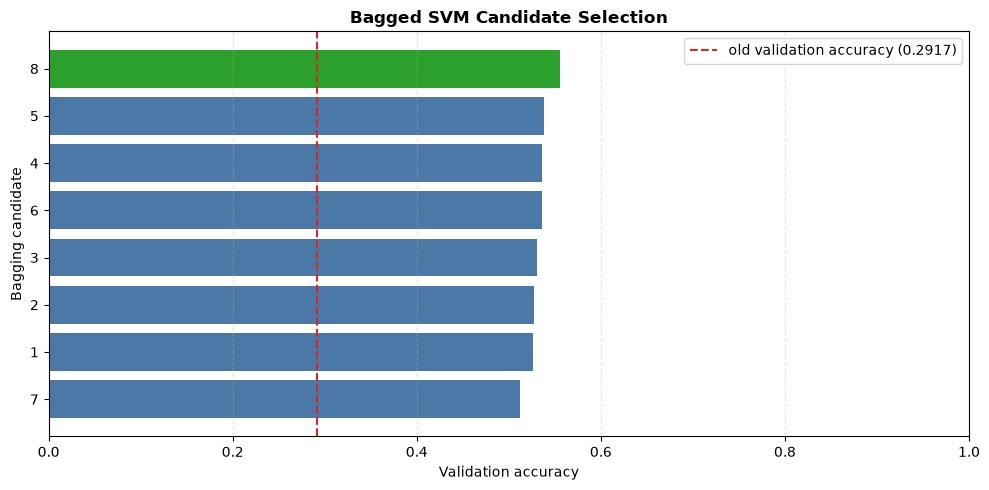

In [22]:
display(ranked.style.format({
    'val_accuracy': '{:.4f}',
    'val_macro_f1': '{:.4f}',
    'val_log_loss': '{:.4f}',
}))

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = ranked.sort_values('val_accuracy')
colours = ['#2ca02c' if int(c) == best_candidate_id else '#4c78a8' for c in plot_df['candidate']]
ax.barh(plot_df['candidate'].astype(str), plot_df['val_accuracy'], color=colours)
ax.axvline(REFERENCE_VAL_ACCURACY, color='#d62728', linestyle='--',
           label=f'old validation accuracy ({REFERENCE_VAL_ACCURACY:.4f})')
ax.set_xlim(0, 1)
ax.set_xlabel('Validation accuracy')
ax.set_ylabel('Bagging candidate')
ax.set_title('Bagged SVM Candidate Selection', fontweight='bold')
ax.legend()
ax.grid(axis='x', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

## 7. Refit the selected bagging configuration on train + validation

The candidate is chosen using validation data. Only after that choice is fixed, train and validation IDs are combined and the final test set is evaluated once.

In [23]:
X_trainval_raw = np.vstack([X_train_raw, X_val_raw])
y_trainval_img = np.concatenate([y_train_img, y_val])
trainval_groups = np.concatenate([train_groups, val_groups])

X_trainval_subject, y_trainval, trainval_subject_ids = aggregate_subjects(
    X_trainval_raw, y_trainval_img, trainval_groups
)

final_scaler = CudaStandardScaler()
X_trainval_scaled = final_scaler.fit_transform(X_trainval_subject)
X_test_final_scaled = final_scaler.transform(X_test_raw)

final_n_pca = min(
    PCA_COMPONENTS,
    X_trainval_scaled.shape[0] - 1,
    X_trainval_scaled.shape[1],
)
final_pca = CudaPCA(n_components=final_n_pca, random_state=SEED)
X_trainval_final = final_pca.fit_transform(X_trainval_scaled)
X_test_final = final_pca.transform(X_test_final_scaled)

final_model = make_bagged_svm(best_config, random_state=SEED + 1000)
final_model.fit(X_trainval_final, y_trainval)

trainval_preds = final_model.predict(X_trainval_final)
test_preds = final_model.predict(X_test_final)
test_proba = final_model.predict_proba(X_test_final)

trainval_acc = accuracy_score(y_trainval, trainval_preds)
test_acc = accuracy_score(y_test, test_preds)
test_macro_f1 = f1_score(y_test, test_preds, average='macro')
test_loss = log_loss(y_test, test_proba, labels=np.arange(len(CLASS_NAMES)))
test_improved = test_acc > REFERENCE_TEST_ACCURACY

print('=' * 60)
print(f'Train + validation accuracy : {trainval_acc:.4f}')
print(f'Old test accuracy           : {REFERENCE_TEST_ACCURACY:.4f}')
print(f'New test accuracy           : {test_acc:.4f}')
print(f'New test macro-F1           : {test_macro_f1:.4f}')
print(f'New test log-loss           : {test_loss:.4f}')
print(f'Test improved               : {test_improved}')
print('=' * 60)

  CUDA member 10/41 | GPU memory 16 MB
  CUDA member 20/41 | GPU memory 16 MB
  CUDA member 30/41 | GPU memory 16 MB
  CUDA member 40/41 | GPU memory 16 MB
  CUDA member 41/41 | GPU memory 16 MB
Train + validation accuracy : 0.7475
Old test accuracy           : 0.5417
New test accuracy           : 0.5467
New test macro-F1           : 0.4208
New test log-loss           : 0.9314
Test improved               : True


## 8. Export misclassified image names to CSV

In [24]:
misclassified_mask = test_preds != y_test
misclassified_indices = np.flatnonzero(misclassified_mask)

misclassified_rows = []
for i in misclassified_indices:
    row = {
        'image_name': Path(test_paths[i]).name,
        'image_path': str(test_paths[i]),
        'image_id': int(test_groups[i]),
        'true_label': CLASS_NAMES[int(y_test[i])],
        'predicted_label': CLASS_NAMES[int(test_preds[i])],
        'confidence': float(test_proba[i, test_preds[i]]),
    }
    for class_index, class_name in enumerate(CLASS_NAMES):
        row[f'probability_{class_name}'] = float(test_proba[i, class_index])
    misclassified_rows.append(row)

misclassified_df = pd.DataFrame(misclassified_rows, columns=[
    'image_name', 'image_path', 'image_id', 'true_label', 'predicted_label',
    'confidence', *[f'probability_{name}' for name in CLASS_NAMES],
])
misclassified_df.to_csv(MISCLASSIFIED_CSV, index=False)

print(f'Misclassified images: {len(misclassified_df)} / {len(y_test)}')
print(f'CSV saved to: {MISCLASSIFIED_CSV}')
display(misclassified_df)

Misclassified images: 578 / 1275
CSV saved to: d:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f2\misclassified_images_bagged_svm.csv


,image_name,image_path,image_id,true_label,predicted_label,confidence,probability_negative,probability_moderate,probability_positive
0,img114_brightness_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,moderate,negative,0.469396,0.469396,0.462602,0.068002
1,img117_autocontrast.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,117,moderate,negative,0.457813,0.457813,0.357075,0.185112
2,img117_brightness_down.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,117,moderate,negative,0.541719,0.541719,0.308691,0.149590
3,img117_color_down.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,117,moderate,negative,0.459237,0.459237,0.353717,0.187046
4,img117_color_up.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,117,moderate,negative,0.463434,0.463434,0.357236,0.179330
...,...,...,...,...,...,...,...,...,...
573,img265.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,265,positive,negative,0.346559,0.346559,0.345475,0.307967
574,img274.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,274,positive,negative,0.479251,0.479251,0.282631,0.238118
575,img297.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,297,positive,moderate,0.418686,0.408092,0.418686,0.173223
576,img35.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,35,positive,moderate,0.436546,0.337255,0.436546,0.226198


## 9. Classification report and confusion matrices

Final Test Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.66      0.73      0.69       782
    moderate       0.29      0.20      0.24       289
    positive       0.33      0.33      0.33       204

    accuracy                           0.55      1275
   macro avg       0.43      0.42      0.42      1275
weighted avg       0.52      0.55      0.53      1275



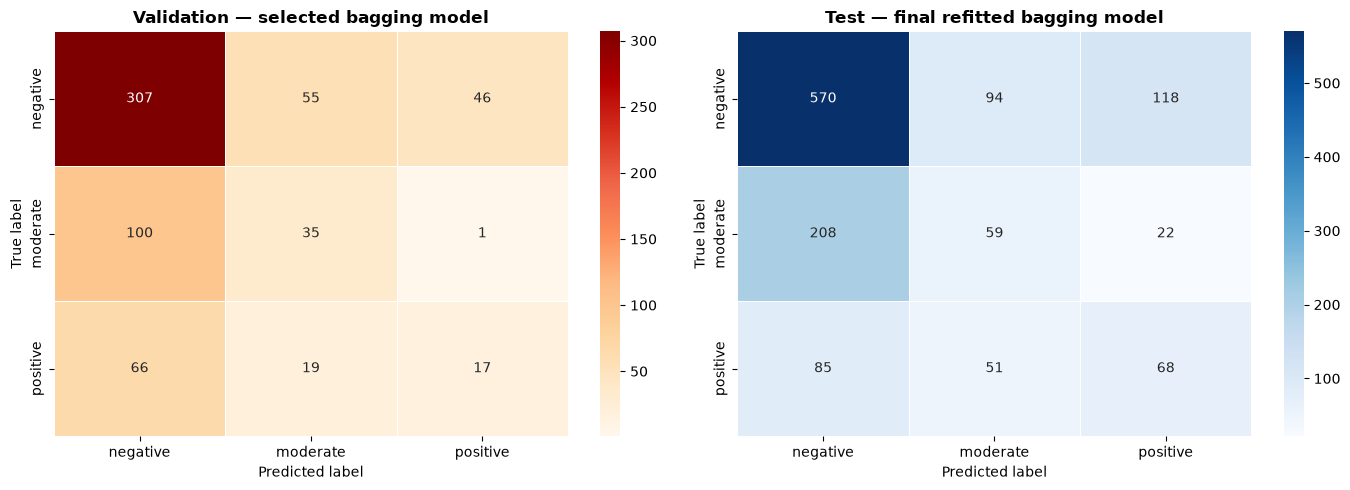

In [25]:
print('Final Test Classification Report')
print('-' * 60)
print(classification_report(
    y_test,
    test_preds,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, true, pred, title, cmap in [
    (axes[0], y_val, val_preds, 'Validation — selected bagging model', 'OrRd'),
    (axes[1], y_test, test_preds, 'Test — final refitted bagging model', 'Blues'),
]:
    matrix = confusion_matrix(true, pred, labels=np.arange(len(CLASS_NAMES)))
    sns.heatmap(
        matrix, annot=True, fmt='d', cmap=cmap,
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        linewidths=0.5, ax=ax,
    )
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')

plt.tight_layout()
plt.show()

## 10. Bias–variance graph

For the selected bagging model, each bootstrap SVM is treated as one fitted learner. Bias² is the squared distance between the ensemble's mean probability vector and the one-hot true label; variance is the average squared spread of member probabilities around that ensemble mean. The held-out validation set is used so this is not an in-sample estimate.

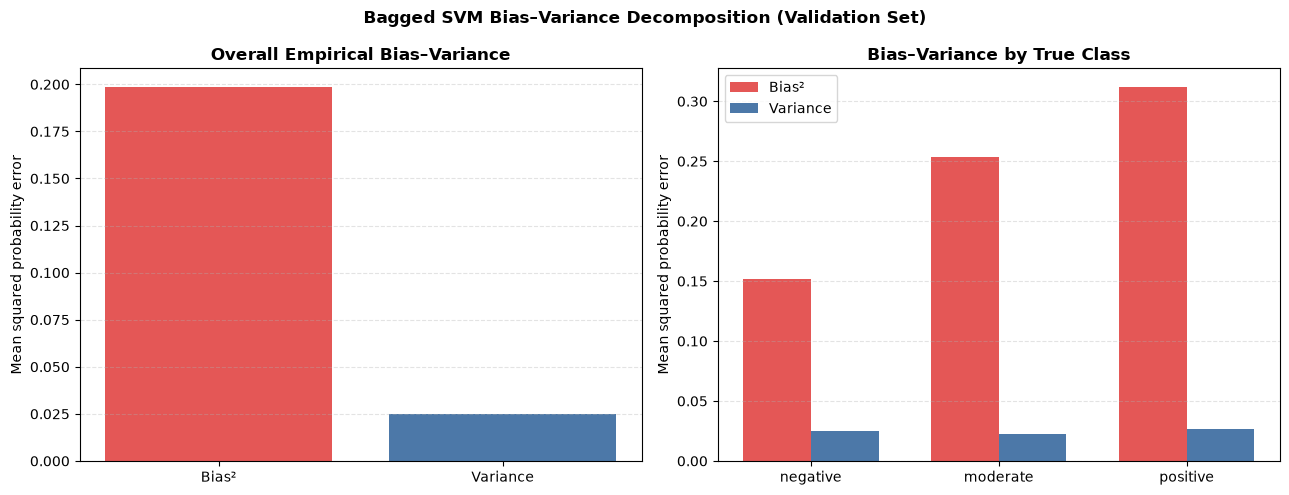

Bias²   : 0.198566
Variance: 0.024888
Graph saved to: d:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f2\bias_variance_bagged_svm.png


In [26]:
def aligned_member_probabilities(bagging_model, X):
    all_probabilities = []
    n_classes = len(CLASS_NAMES)
    for estimator, feature_indices in zip(
        bagging_model.estimators_, bagging_model.estimators_features_
    ):
        raw = estimator.predict_proba(X[:, feature_indices])
        aligned = np.zeros((len(X), n_classes), dtype=np.float64)
        for source_column, class_index in enumerate(estimator.classes_):
            aligned[:, int(class_index)] = raw[:, source_column]
        all_probabilities.append(aligned)
    return np.stack(all_probabilities, axis=0)

member_proba = aligned_member_probabilities(selection_model, X_val)
mean_proba = member_proba.mean(axis=0)
one_hot = np.eye(len(CLASS_NAMES))[y_val]

bias_squared_per_sample = np.mean((mean_proba - one_hot) ** 2, axis=1)
variance_per_sample = np.mean(
    np.mean((member_proba - mean_proba[None, :, :]) ** 2, axis=2),
    axis=0,
)

overall_bias_squared = bias_squared_per_sample.mean()
overall_variance = variance_per_sample.mean()

class_bias = []
class_variance = []
for class_index in range(len(CLASS_NAMES)):
    mask = y_val == class_index
    class_bias.append(bias_squared_per_sample[mask].mean())
    class_variance.append(variance_per_sample[mask].mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    ['Bias²', 'Variance'],
    [overall_bias_squared, overall_variance],
    color=['#e45756', '#4c78a8'],
)
axes[0].set_title('Overall Empirical Bias–Variance', fontweight='bold')
axes[0].set_ylabel('Mean squared probability error')
axes[0].grid(axis='y', linestyle='--', alpha=0.35)

positions = np.arange(len(CLASS_NAMES))
width = 0.36
axes[1].bar(positions - width/2, class_bias, width, label='Bias²', color='#e45756')
axes[1].bar(positions + width/2, class_variance, width, label='Variance', color='#4c78a8')
axes[1].set_xticks(positions)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_title('Bias–Variance by True Class', fontweight='bold')
axes[1].set_ylabel('Mean squared probability error')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.35)

fig.suptitle('Bagged SVM Bias–Variance Decomposition (Validation Set)', fontweight='bold')
plt.tight_layout()
plt.savefig(BIAS_VARIANCE_PNG, dpi=160, bbox_inches='tight')
plt.show()

print(f'Bias²   : {overall_bias_squared:.6f}')
print(f'Variance: {overall_variance:.6f}')
print(f'Graph saved to: {BIAS_VARIANCE_PNG}')

## 11. Performance gate and model save

The CSV and diagnostic plots are always produced. The model artifact is saved only if the validation-selected bagging workflow strictly beats both recorded accuracies from the previous notebook.

In [27]:
performance_gate_passed = validation_improved and test_improved

if not performance_gate_passed:
    raise RuntimeError(
        'Performance gate failed; the old model was NOT overwritten. '
        f'Validation: {selection_val_acc:.4f} vs {REFERENCE_VAL_ACCURACY:.4f}; '
        f'test: {test_acc:.4f} vs {REFERENCE_TEST_ACCURACY:.4f}. '
        'The misclassification CSV and bias–variance plot were still created.'
    )

artifact = {
    'model': final_model,
    'scaler': final_scaler,
    'pca': final_pca,
    'best_config': best_config,
    'candidate_results': candidate_results,
    'class_names': CLASS_NAMES,
    'image_size': IMAGE_SIZE,
    'feature_type': 'HOG + HSV histograms + spatial RGB + colour moments',
    'selection_val_accuracy': selection_val_acc,
    'test_accuracy': test_acc,
    'test_macro_f1': test_macro_f1,
    'reference_val_accuracy': REFERENCE_VAL_ACCURACY,
    'reference_test_accuracy': REFERENCE_TEST_ACCURACY,
    'label_source': str(source_path),
}

with open(MODEL_PATH, 'wb') as file:
    pickle.dump(artifact, file)

print('PERFORMANCE GATE PASSED')
print(f'Model saved to: {MODEL_PATH}')
print(f'Validation gain: {selection_val_acc - REFERENCE_VAL_ACCURACY:+.4f}')
print(f'Test gain      : {test_acc - REFERENCE_TEST_ACCURACY:+.4f}')

PERFORMANCE GATE PASSED
Model saved to: d:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f2\rajuk_bagged_svm.pkl
Validation gain: +0.2640
Test gain      : +0.0050


## 12. Load the saved model and predict a new image

In [28]:
def load_artifact(model_path=MODEL_PATH):
    with open(model_path, 'rb') as file:
        return pickle.load(file)

def predict_image(image_path, trained_artifact):
    features = extract_image_features(image_path).reshape(1, -1)
    features = trained_artifact['scaler'].transform(features)
    features = trained_artifact['pca'].transform(features)
    probabilities = trained_artifact['model'].predict_proba(features)[0]
    predicted_index = int(np.argmax(probabilities))
    return {
        'prediction': trained_artifact['class_names'][predicted_index],
        'confidence': float(probabilities[predicted_index]),
        'probabilities': dict(zip(
            trained_artifact['class_names'], probabilities.astype(float)
        )),
    }

# Example:
# loaded_artifact = load_artifact()
# result = predict_image(DRIVE_BASE / 'new_image.jpg', loaded_artifact)
# print(result)